# Miser pour le gain, janvier 2025 – août 2026

## La question

Désigner le vainqueur n'est pas la même chose que rendre plus d'euros qu'on en a misés.
Un modèle peut trouver le favori un peu plus souvent et perdre de l'argent, parce que la
cote de ce cheval est courte et que le PMU prélève déjà sa part.

Ici on cherche la règle de mise qui **maximise les gains**. Le cheval intéressant n'est
donc pas forcément le plus performant. C'est celui dont **la cote paie plus que ses chances
réelles**. Cet écart peut se trouver sur un favori trop délaissé. Il peut aussi se trouver
sur un outsider — un cheval que le public néglige, et dont le prix est alors trop généreux.

Ce n'est pas un système de jeu. On mise **1 € au simple gagnant**, à plat, sur des courses
déjà courues. Le prix retenu est la **cote au départ** : c'est ce que le pari aurait
rapporté s'il avait été tenu jusqu'au top. Les mouvements de cote dans la journée, le placé
et les paris combinés restent dehors.

La période est celle du panorama : du **1er janvier 2025 au 31 août 2026**. On apprend sur
le premier semestre 2025, on recale les chances de juillet à décembre 2025, et on juge sur
**2026**, jusqu'au 31 août.


## Sommaire

1. [Deux façons de juger une mise](#juger)
2. [Ce que rapporte vraiment chaque prix](#prix)
3. [Favori, deuxième prix, outsider](#regles)
4. [Choisir l'espérance plutôt que le vainqueur](#esperance)
5. [Passer son tour quand le prix n'est pas là](#passer)
6. [Ce qu'il ne faut pas conclure trop vite](#limites)
7. [Verdict](#verdict)


In [1]:
import sys
import warnings
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "pmu").exists():
    project_root = project_root.parent
sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import design_system as ds
from dataset.load_jeu_modelisation import load_jeu_modelisation
from pmu.types.types import ProgrammeIdentifier
from pmu.utils import programme_date_to_date

warnings.filterwarnings("ignore", category=FutureWarning)
THEME = ds.apply_theme("light")

start_date = ProgrammeIdentifier("01012025")
end_date = ProgrammeIdentifier("31082026")
debut = pd.Timestamp(programme_date_to_date(str(start_date)))
fin = pd.Timestamp(programme_date_to_date(str(end_date)))


In [2]:
ESPACE = "\u202f"


def nombre(valeur, decimales=0, unite=""):
    if pd.isna(valeur):
        return "—"
    texte = f"{valeur:,.{decimales}f}".replace(",", ESPACE).replace(".", ",")
    return f"{texte}{unite}"


def tableau(frame, titre=None, formats=None, barres=None, gradient=None, precision=0):
    styler = frame.style.set_table_styles(ds.table_css("light"))
    if titre:
        styler = styler.set_caption(titre)
    if formats:
        styler = styler.format(formats, na_rep="—")
    else:
        styler = styler.format(precision=precision, thousands=ESPACE, decimal=",", na_rep="—")
    if barres:
        styler = styler.bar(subset=barres, color=THEME["chart_3"], align="left", height=62, width=96)
    if gradient:
        styler = styler.background_gradient(
            cmap=ds.diverging_cmap("light"), subset=gradient, vmin=-1, vmax=1
        )
    return styler


def chiffres_cles(valeurs: dict, titre: str):
    frame = pd.DataFrame({"": list(valeurs.values())}, index=list(valeurs.keys()))
    return tableau(frame, titre, formats={"": "{}"})


def figure(titre: str, figsize=(11, 4.4)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(titre)
    return fig, ax


def une_mise(frame, score, croissant=False):
    ordre = frame.assign(_score=np.asarray(score)).sort_values("_score", ascending=croissant)
    return ordre.groupby("course_id", observed=True).head(1)


def decrire(choix, nom, courses):
    pay = np.where(choix["gagnant"].to_numpy(), choix["cote_utile"].to_numpy(), 0.0)
    n = len(pay)
    if n == 0:
        return {
            "Règle": nom,
            "Paris": 0,
            "Courses jouées": 0.0,
            "Vainqueur trouvé": np.nan,
            "Euros rendus pour 1 €": np.nan,
            "Marge de hasard (±)": np.nan,
            "Cote médiane": np.nan,
            "Rang de prix médian": np.nan,
        }
    se = pay.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return {
        "Règle": nom,
        "Paris": n,
        "Courses jouées": n / courses,
        "Vainqueur trouvé": float(choix["gagnant"].mean()),
        "Euros rendus pour 1 €": float(pay.mean()),
        "Marge de hasard (±)": float(2 * se),
        "Cote médiane": float(choix["cote_utile"].median()),
        "Rang de prix médian": float(choix["rang_prix"].median()),
    }


FORMATS_REGLES = {
    "Paris": lambda v: nombre(v),
    "Courses jouées": lambda v: nombre(v * 100, 1, " %"),
    "Vainqueur trouvé": lambda v: nombre(v * 100, 1, " %"),
    "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
    "Marge de hasard (±)": lambda v: nombre(v, 3, " €"),
    "Cote médiane": lambda v: nombre(v, 1),
    "Rang de prix médian": lambda v: nombre(v, 1),
}


<a id="juger"></a>
## 1. Deux façons de juger une mise

Une règle peut être jugée de deux manières, et elles ne désignent pas le même cheval.

- **Trouver le vainqueur.** On compte les courses où le cheval choisi finit premier. Le favori
  gagne souvent. C'est flatteur, et insuffisant.
- **Rendre de l'argent.** On mise 1 €. Si le cheval gagne, on récupère sa cote. Sinon, on
  récupère 0. La moyenne de ces retours dit si la règle enrichit ou appauvrit. **1 € rendu
  signifie qu'on récupère sa mise. En dessous, on perd.**

Un favori à cote 2 qui gagne une fois sur trois rend \(0{,}33 \times 2 = 0{,}67\) €. Un
outsider à cote 15 qui gagne une fois sur vingt rend \(0{,}05 \times 15 = 0{,}75\) €. Le
second a raison bien moins souvent, et peut rendre davantage. Le gain ne vient pas de la
victoire : il vient du **prix**.

La cote annonce déjà une chance : un cheval à 5 est affiché à 1 chance sur 5. Cette annonce
est trop optimiste dans l'ensemble, parce que le prélèvement est dans le prix. Sur une
course, la somme des « 1 / cote » dépasse 1. Pour gagner, il ne suffit pas d'être d'accord
avec la cote. Il faut un cheval dont les chances réelles **dépassent** ce que sa cote paie.


In [3]:
brut = load_jeu_modelisation(start_date, end_date)
brut["gains_euros"] = brut["gains_carriere"] / 100
brut["taux_victoire"] = np.where(
    brut["nombre_courses"] > 0, brut["nombre_victoires"] / brut["nombre_courses"], np.nan
)
brut["taux_place"] = np.where(
    brut["nombre_courses"] > 0, brut["nombre_places"] / brut["nombre_courses"], np.nan
)
brut["log_gains"] = np.log10(brut["gains_euros"].clip(lower=1))
brut["cote_utile"] = brut["cote_directe"].where(brut["cote_directe"].between(1, 998))
brut["log_cote"] = np.log(brut["cote_utile"])
brut["gagnant"] = brut["ordre_arrivee"].eq(1)

courses_avec_vainqueur = brut.loc[brut["gagnant"], "course_id"].unique()
jeu = brut[brut["course_id"].isin(courses_avec_vainqueur)].copy()

prix = jeu.dropna(
    subset=["cote_utile", "taux_victoire", "taux_place", "age", "nombre_partants", "log_gains"]
).copy()
encore_gagnee = prix.loc[prix["gagnant"], "course_id"].unique()
prix = prix[prix["course_id"].isin(encore_gagnee)].copy()
prix["place_corde_connue"] = prix["place_corde"].notna().astype(float)
prix["place_corde"] = prix["place_corde"].fillna(prix["nombre_partants"] / 2)
prix["log_partants"] = np.log(prix["nombre_partants"].clip(lower=1))
prix["rang_prix"] = prix.groupby("course_id")["cote_utile"].rank(method="first", ascending=True)
prix["chance_cote"] = 1 / prix["cote_utile"]
prix["retour"] = np.where(prix["gagnant"], prix["cote_utile"], 0.0)

somme_chances = prix.groupby("course_id")["chance_cote"].sum()
premier = pd.to_datetime(prix["date_programme"]).min()
dernier = pd.to_datetime(prix["date_programme"]).max()
display(
    chiffres_cles(
        {
            "Période demandée": f"{debut:%d/%m/%Y} → {fin:%d/%m/%Y}",
            "Première course utilisable": f"{premier:%d/%m/%Y}",
            "Dernière course utilisable": f"{dernier:%d/%m/%Y}",
            "Journées distinctes": nombre(pd.to_datetime(prix["date_programme"]).dt.normalize().nunique()),
            "Courses utilisables": nombre(prix["course_id"].nunique()),
            "Partants avec une cote": nombre(len(prix)),
            "Somme des chances affichées, médiane": nombre(somme_chances.median(), 2),
            "Courses où cette somme dépasse 1": f"{nombre((somme_chances > 1).mean() * 100, 1)} %",
        },
        "La marge déjà présente dans les cotes",
    )
)


,
Période demandée,01/01/2025 → 31/08/2026
Première course utilisable,01/01/2025
Dernière course utilisable,31/08/2026
Journées distinctes,608
Courses utilisables,27 133
Partants avec une cote,291 972
"Somme des chances affichées, médiane","1,16"
Courses où cette somme dépasse 1,"93,9 %"


**À retenir.** Du 1er janvier 2025 au 31 août 2026, 27 133 courses sont utilisables, sur
608 journées. La somme des chances affichées vaut 1,16 en médiane, et elle dépasse 1 dans
94 % des courses. Le marché ne propose pas un prix équitable : **une partie de chaque euro
misé est déjà prélevée**. Une règle qui se contente de suivre la cote part avec ce handicap.


<a id="prix"></a>
## 2. Ce que rapporte vraiment chaque prix

Avant tout modèle : **si l'on achète toujours le même genre de cote, combien revient 1 € ?**
Chaque partant est une mise d'1 €. S'il gagne, on encaisse sa cote. On regroupe les chevaux
par tranche de prix, du grand favori au très gros outsider.

La colonne « chances affichées » est la moyenne de 1 / cote dans la tranche. Si les chevaux
gagnaient aussi souvent que leur cote le dit, les euros rendus vaudraient 1. L'écart entre
le taux de victoire et ces chances dit si le prix était trop court ou trop généreux.


,Partants,Taux de victoire,Chances affichées,Euros rendus pour 1 €,Écart de chances
tranche,,,,,
1 à 2,4 213,"54,9 %","60,7 %","0,903 €","-5,8 points"
"2 à 3,5",17 679,"33,5 %","37,1 %","0,902 €","-3,6 points"
"3,5 à 6",34 804,"19,9 %","21,9 %","0,911 €","-2,0 points"
6 à 10,46 457,"11,8 %","13,0 %","0,904 €","-1,2 points"
10 à 18,57 489,"6,7 %","7,9 %","0,850 €","-1,2 points"
18 à 40,65 235,"3,2 %","4,0 %","0,796 €","-0,8 points"
40 et plus,66 095,"0,9 %","1,4 %","0,609 €","-0,5 points"


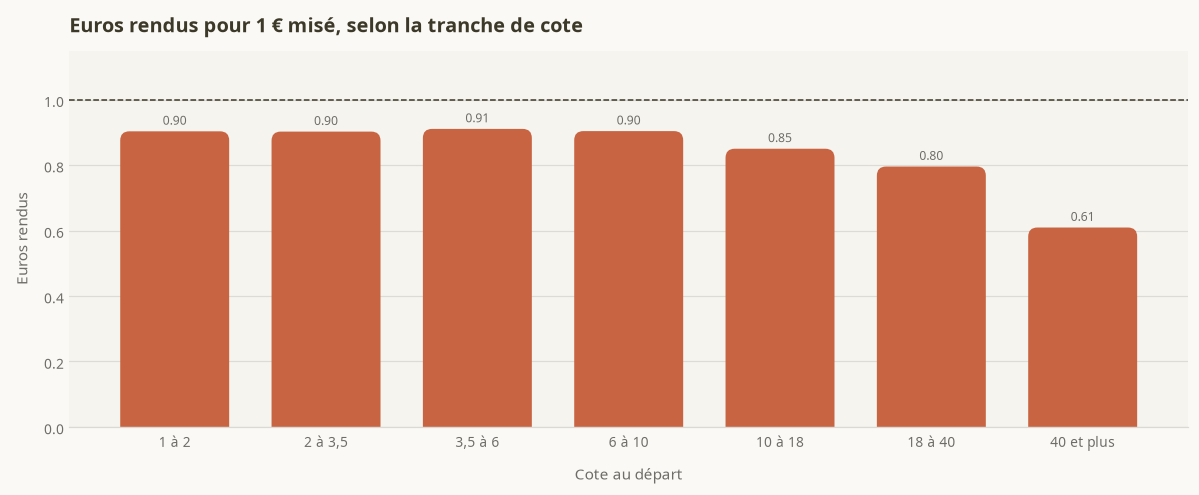

In [4]:
bornes = [1, 2, 3.5, 6, 10, 18, 40, 1000]
etiquettes = ["1 à 2", "2 à 3,5", "3,5 à 6", "6 à 10", "10 à 18", "18 à 40", "40 et plus"]
prix["tranche"] = pd.cut(prix["cote_utile"], bornes, right=False, labels=etiquettes)

par_prix = prix.groupby("tranche", observed=True).agg(
    partants=("cote_utile", "size"),
    taux=("gagnant", "mean"),
    chances=("chance_cote", "mean"),
    euros=("retour", "mean"),
)
par_prix = par_prix.rename(
    columns={
        "partants": "Partants",
        "taux": "Taux de victoire",
        "chances": "Chances affichées",
        "euros": "Euros rendus pour 1 €",
    }
)
par_prix["Écart de chances"] = par_prix["Taux de victoire"] - par_prix["Chances affichées"]

display(
    tableau(
        par_prix,
        "Un euro misé sur chaque partant, selon sa cote au départ",
        formats={
            "Partants": lambda v: nombre(v),
            "Taux de victoire": lambda v: nombre(v * 100, 1, " %"),
            "Chances affichées": lambda v: nombre(v * 100, 1, " %"),
            "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
            "Écart de chances": lambda v: nombre(v * 100, 1, " points"),
        },
    )
)

fig, ax = figure("Euros rendus pour 1 € misé, selon la tranche de cote", (11, 4.6))
valeurs = par_prix["Euros rendus pour 1 €"]
ax.bar(valeurs.index.astype(str), valeurs.to_numpy(), color=THEME["primary"], width=0.72)
ax.axhline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ds.annotate_bars(ax, fmt="{:.2f}")
ds.rounded_bars(ax)
ax.set_ylabel("Euros rendus")
ax.set_xlabel("Cote au départ")
ax.set_ylim(0, max(1.15, float(valeurs.max()) * 1.25))
fig.tight_layout()


**À retenir.** Aucune tranche ne rend 1 €. Les prix courts tournent autour de 0,90 €. Le
rendement baisse ensuite, jusqu'à 0,61 € au-delà de 40. Partout, les chevaux gagnent moins
souvent que leur cote ne l'annonce : l'écart est de 6 points chez les grands favoris, et il
reste négatif chez les outsiders. **Acheter un prix élevé parce qu'il est élevé est le plus
mauvais achat du tableau.** L'outsider n'est intéressant que s'il est mal payé par rapport
à ses chances, pas parce que sa cote est haute.


<a id="regles"></a>
## 3. Favori, deuxième prix, outsider

Les tranches mélangent des courses différentes. Ici on joue **un seul cheval par course**,
choisi uniquement d'après son prix.

Le rang 1 est le favori, le cheval à la cote la plus basse. Le rang 2 est le deuxième prix,
et ainsi de suite. « Le plus gros outsider » est le cheval à la cote la plus haute de la
course, quel que soit le nombre de partants.

La marge de hasard indique de combien le résultat pourrait encore bouger pour cette seule
raison. Elle est grande quand on gagne rarement et très gros.


,Paris,Courses jouées,Vainqueur trouvé,Euros rendus pour 1 €,Marge de hasard (±),Cote médiane,Rang de prix médian
Règle,,,,,,,
Rang 1 dans les prix,27 133,"100,0 %","34,2 %","0,935 €","0,018 €","2,9","1,0"
Rang 2 dans les prix,27 094,"99,9 %","19,2 %","0,916 €","0,025 €","4,8","2,0"
Rang 3 dans les prix,27 019,"99,6 %","13,6 %","0,915 €","0,031 €","6,8","3,0"
Rang 4 dans les prix,26 890,"99,1 %","9,4 %","0,834 €","0,033 €","9,1","4,0"
Rang 5 dans les prix,26 544,"97,8 %","7,2 %","0,835 €","0,040 €","12,0","5,0"
Rang 6 dans les prix,25 742,"94,9 %","5,5 %","0,816 €","0,046 €","15,0","6,0"
Le plus gros outsider,27 133,"100,0 %","1,6 %","0,604 €","0,079 €","73,0","11,0"


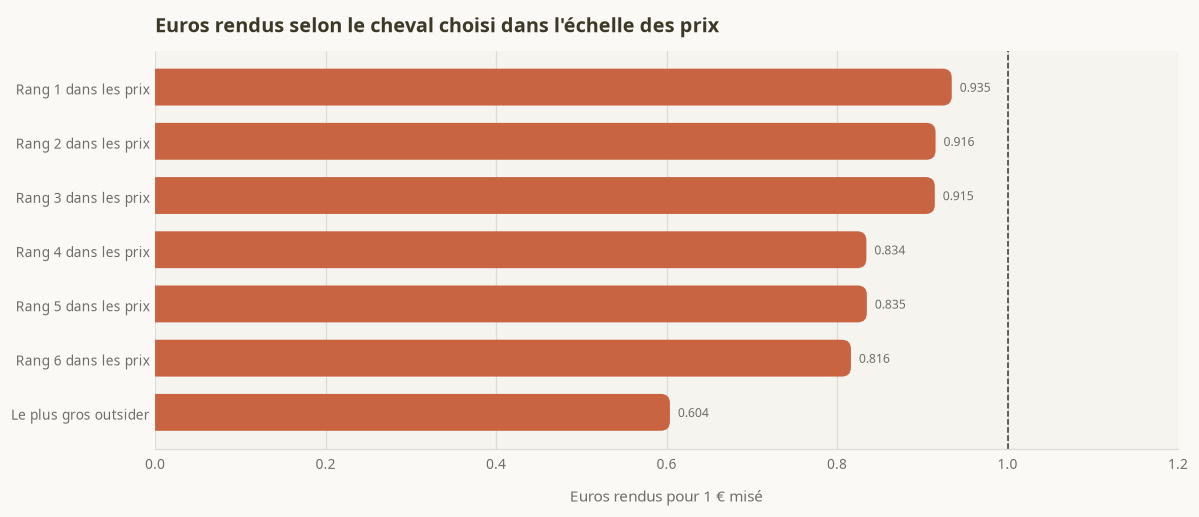

In [5]:
courses = prix["course_id"].nunique()
regles_prix = [
    decrire(prix[prix["rang_prix"] == rang], f"Rang {rang} dans les prix", courses) for rang in range(1, 7)
]
outsider = prix.loc[prix.groupby("course_id")["rang_prix"].transform("max") == prix["rang_prix"]]
regles_prix.append(decrire(outsider, "Le plus gros outsider", courses))
bilan_prix = pd.DataFrame(regles_prix).set_index("Règle")
display(
    tableau(
        bilan_prix,
        "Une mise d'1 € par course, le cheval choisi d'après son seul prix",
        formats=FORMATS_REGLES,
    )
)

fig, ax = figure("Euros rendus selon le cheval choisi dans l'échelle des prix", (11, 4.8))
serie = bilan_prix["Euros rendus pour 1 €"]
ax.barh(serie.index.astype(str)[::-1], serie.to_numpy()[::-1], color=THEME["primary"], height=0.68)
ax.axvline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ds.annotate_bars(ax, orientation="horizontal", fmt="{:.3f}")
ds.rounded_bars(ax, orientation="horizontal")
ax.set_xlabel("Euros rendus pour 1 € misé")
ax.set_xlim(0, max(1.2, float(serie.max()) * 1.25))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()


**À retenir.** Plus on descend dans l'échelle des prix, plus l'argent rendu baisse, et la
marge de hasard est trop étroite pour que ce soit un accident. Le favori trouve le vainqueur
dans 34 % des courses et rend 0,94 € : c'est la moins mauvaise des règles mécaniques, et
c'est encore une perte. Le 4e prix, qui pouvait sembler intéressant sur quelques journées,
rend 0,83 € sur l'ensemble. Le plus gros outsider rend 0,60 €, cote médiane 73, avec une
marge qui ne remonte pas jusqu'à la mise. **Allonger le prix de façon automatique détruit
la mise. Cela ne constitue pas une chasse au value.**


<a id="esperance"></a>
## 4. Choisir l'espérance plutôt que le vainqueur

Une cote n'est intéressante que comparée à une chance. On estime donc, pour chaque cheval,
une probabilité de gagner. Deux estimations simples :

- **Profil seul** : âge, palmarès, gains, corde, nombre de partants. La cote n'entre pas.
  Ce modèle peut contredire le marché, et donc désigner un cheval que le prix néglige.
- **Cote et profil** : les mêmes informations, plus la cote. Il colle au marché.

Les chances sont recollées à la réalité de **juillet à décembre 2025**, pour qu'une
probabilité de 10 % veuille bien dire « gagne environ une fois sur dix ». Sans ce recalage,
un modèle gonfle les chances des chevaux rares et fabrique de fausses bonnes affaires.

L'espérance d'une mise d'1 € est : **chances estimées × cote**. Au-dessus de 1, le modèle
juge que le prix paie trop. Sur 2026 seulement, on compare deux gestes :

- jouer le cheval **le plus probable** de la course (la chasse au vainqueur) ;
- jouer le cheval à **l'espérance la plus haute** (la chasse au prix).

Le second geste peut choisir un outsider. Il le fait quand le modèle lui donne plus de
chances que sa cote, pas parce que sa cote est haute. Si les chances estimées baissent
moins vite que 1 / cote, l'espérance désigne toujours le prix le plus long.


In [6]:
PROFIL = [
    "age",
    "taux_victoire",
    "taux_place",
    "log_gains",
    "nombre_courses",
    "place_corde",
    "place_corde_connue",
    "log_partants",
]
AVEC_COTE = ["log_cote"] + PROFIL

dates = pd.to_datetime(prix["date_programme"])
apprentissage = prix.loc[dates < "2025-07-01"]
calage = prix.loc[(dates >= "2025-07-01") & (dates < "2026-01-01")]
test = prix.loc[dates >= "2026-01-01"].copy()


def chances_recales(colonnes):
    pipeline = Pipeline(
        [
            ("echelle", StandardScaler()),
            ("modele", LogisticRegression(max_iter=500)),
        ]
    )
    pipeline.fit(apprentissage[colonnes], apprentissage["gagnant"].astype(int))
    brut_calage = pipeline.predict_proba(calage[colonnes])[:, 1]
    brut_test = pipeline.predict_proba(test[colonnes])[:, 1]
    recalage = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
    recalage.fit(brut_calage, calage["gagnant"].astype(int))
    return pd.Series(recalage.predict(brut_test), index=test.index)


test["p_profil"] = chances_recales(PROFIL)
test["p_plein"] = chances_recales(AVEC_COTE)
test["ev_profil"] = test["p_profil"] * test["cote_utile"]
test["ev_plein"] = test["p_plein"] * test["cote_utile"]

display(
    chiffres_cles(
        {
            "Apprentissage": f"{pd.to_datetime(apprentissage['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(apprentissage['date_programme']).max():%d/%m/%Y}",
            "Recalage des chances": f"{pd.to_datetime(calage['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(calage['date_programme']).max():%d/%m/%Y}",
            "Jugement": f"{pd.to_datetime(test['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(test['date_programme']).max():%d/%m/%Y}",
            "Courses d'apprentissage": nombre(apprentissage["course_id"].nunique()),
            "Courses de recalage": nombre(calage["course_id"].nunique()),
            "Courses de jugement": nombre(test["course_id"].nunique()),
            "Partants jugés": nombre(len(test)),
        },
        "Trois périodes successives, pour ne pas juger le modèle sur ce qu'il a déjà vu",
    )
)


,
Apprentissage,01/01/2025 → 30/06/2025
Recalage des chances,01/07/2025 → 31/12/2025
Jugement,01/01/2026 → 31/08/2026
Courses d'apprentissage,7 887
Courses de recalage,7 775
Courses de jugement,11 471
Partants jugés,121 799


In [7]:
test["tranche"] = pd.cut(test["cote_utile"], bornes, right=False, labels=etiquettes)
lecture = test.groupby("tranche", observed=True).agg(
    partants=("cote_utile", "size"),
    gagne=("gagnant", "mean"),
    cote=("chance_cote", "mean"),
    profil=("p_profil", "mean"),
    euros=("retour", "mean"),
    esperance=("ev_profil", "mean"),
)
lecture = lecture.rename(
    columns={
        "partants": "Partants",
        "gagne": "A vraiment gagné",
        "cote": "Chances de la cote",
        "profil": "Chances du profil",
        "euros": "Euros rendus pour 1 €",
        "esperance": "Espérance selon le profil",
    }
)
display(
    tableau(
        lecture,
        "En 2026, les chances du profil comparées à celles de la cote",
        formats={
            "Partants": lambda v: nombre(v),
            "A vraiment gagné": lambda v: nombre(v * 100, 1, " %"),
            "Chances de la cote": lambda v: nombre(v * 100, 1, " %"),
            "Chances du profil": lambda v: nombre(v * 100, 1, " %"),
            "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
            "Espérance selon le profil": lambda v: nombre(v, 2, " €"),
        },
    )
)


,Partants,A vraiment gagné,Chances de la cote,Chances du profil,Euros rendus pour 1 €,Espérance selon le profil
tranche,,,,,,
1 à 2,1 798,"56,1 %","60,5 %","15,7 %","0,922 €","0,26 €"
"2 à 3,5",7 701,"33,4 %","37,2 %","12,8 %","0,895 €","0,35 €"
"3,5 à 6",14 515,"20,0 %","21,9 %","11,4 %","0,914 €","0,53 €"
6 à 10,18 847,"12,2 %","13,0 %","10,5 %","0,937 €","0,82 €"
10 à 18,23 489,"6,9 %","7,9 %","9,6 %","0,874 €","1,25 €"
18 à 40,26 904,"3,1 %","4,0 %","8,7 %","0,765 €","2,30 €"
40 et plus,28 545,"1,0 %","1,4 %","7,0 %","0,626 €","6,09 €"


In [8]:
n_test = test["course_id"].nunique()
favori = une_mise(test, test["cote_utile"], croissant=True)
gros = une_mise(test, test["cote_utile"], croissant=False)
lignes = [
    decrire(favori, "Favori (plus basse cote)", n_test),
    decrire(gros, "Plus gros outsider", n_test),
    decrire(une_mise(test, test["p_profil"]), "Plus probable — profil seul", n_test),
    decrire(une_mise(test, test["ev_profil"]), "Plus forte espérance — profil seul", n_test),
    decrire(une_mise(test, test["p_plein"]), "Plus probable — cote et profil", n_test),
    decrire(une_mise(test, test["ev_plein"]), "Plus forte espérance — cote et profil", n_test),
]
bilan_modeles = pd.DataFrame(lignes).set_index("Règle")
display(
    tableau(
        bilan_modeles,
        "2026 : chasser le vainqueur, ou chasser le prix",
        formats=FORMATS_REGLES,
    )
)


,Paris,Courses jouées,Vainqueur trouvé,Euros rendus pour 1 €,Marge de hasard (±),Cote médiane,Rang de prix médian
Règle,,,,,,,
Favori (plus basse cote),11 471,"100,0 %","34,7 %","0,936 €","0,027 €","2,8","1,0"
Plus gros outsider,11 471,"100,0 %","1,7 %","0,688 €","0,137 €","74,0","11,0"
Plus probable — profil seul,11 471,"100,0 %","20,0 %","0,879 €","0,051 €","5,9","3,0"
Plus forte espérance — profil seul,11 471,"100,0 %","1,8 %","0,689 €","0,136 €","68,0","10,0"
Plus probable — cote et profil,11 471,"100,0 %","34,5 %","0,933 €","0,027 €","2,9","1,0"
Plus forte espérance — cote et profil,11 471,"100,0 %","20,0 %","0,931 €","0,051 €","5,0","2,0"


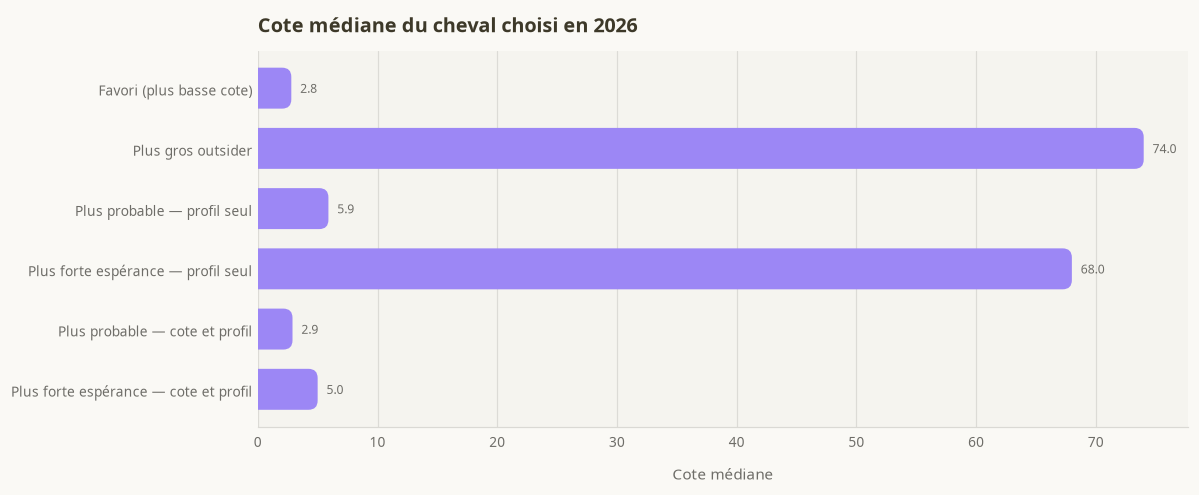

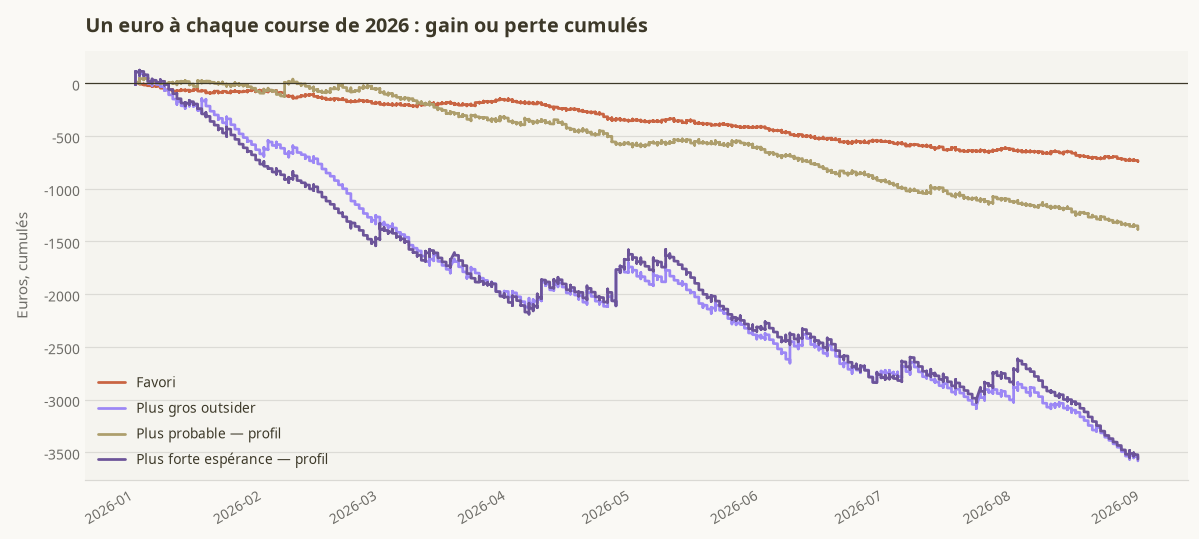

In [9]:
fig, ax = figure("Cote médiane du cheval choisi en 2026", (11, 4.6))
cotes = bilan_modeles["Cote médiane"]
ax.barh(cotes.index.astype(str)[::-1], cotes.to_numpy()[::-1], color=THEME["chart_2"], height=0.68)
ds.annotate_bars(ax, orientation="horizontal", fmt="{:.1f}")
ds.rounded_bars(ax, orientation="horizontal")
ax.set_xlabel("Cote médiane")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()


def cumul(choix):
    classe = choix.sort_values(["date_programme", "course_id"])
    flux = np.where(classe["gagnant"].to_numpy(), classe["cote_utile"].to_numpy() - 1.0, -1.0)
    return classe["date_programme"], np.cumsum(flux)


fig, ax = figure("Un euro à chaque course de 2026 : gain ou perte cumulés", (11, 5))
traces = [
    ("Favori", favori),
    ("Plus gros outsider", gros),
    ("Plus probable — profil", une_mise(test, test["p_profil"])),
    ("Plus forte espérance — profil", une_mise(test, test["ev_profil"])),
]
for nom, choix in traces:
    dates_courbe, courbe = cumul(choix)
    ax.plot(dates_courbe, courbe, linewidth=1.8, label=nom)
ax.axhline(0, color=THEME["foreground"], linewidth=0.8)
ax.set_ylabel("Euros, cumulés")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout()


**À retenir.** Le profil seul ne baisse pas assez vite quand le prix s'allonge. En 2026, il
prête 7 % de chances aux chevaux à plus de 40, qui en gagnent 1 %. L'espérance qu'il leur
attribue atteint 6 €, alors que 1 € misé sur eux n'en rend que 0,63. La règle « plus forte
espérance » choisit donc le même genre de cheval que le plus gros outsider : cote médiane
68, rang 10, 0,69 € rendus. Ce n'est pas une affaire détectée. C'est la formule qui, faute
d'une chance bien calibrée, **retombe sur le prix le plus haut**.

Le modèle qui voit la cote, quand on lui demande le plus probable, retrouve le favori :
34,5 % de vainqueurs, 0,93 €, cote médiane 2,9. Lui demander l'espérance allonge un peu le
prix (médiane 5, rang 2) et rend 0,93 € aussi. On change de cheval. On ne bat pas le
prélèvement. Sur 11 471 courses, la marge de hasard de ces deux règles (±0,03 € et ±0,05 €)
reste sous 1 €.


<a id="passer"></a>
## 5. Passer son tour quand le prix n'est pas là

Jusqu'ici, chaque course reçoit une mise. Même quand aucun cheval n'a d'espérance au-dessus
de 1, on joue le moins mauvais. Un parieur qui cherche un prix peut **ne pas jouer**.

On reprend l'espérance du profil seul — le seul modèle capable de contredire la cote — et
l'on ne mise que si le meilleur cheval de la course dépasse un seuil. 1,00 veut dire « le
modèle voit au moins le retour de la mise ». 1,20 veut dire « il exige 20 centimes d'avance
avant de sortir 1 € ». Les seuils ne sont pas choisis parce que l'un d'eux gagne : on les
affiche tous. Un seuil qui ne joue presque plus n'est pas une découverte, c'est un
échantillon trop mince.


,Paris,Courses jouées,Vainqueur trouvé,Euros rendus pour 1 €,Marge de hasard (±),Cote médiane,Rang de prix médian
Règle,,,,,,,
"Espérance d'au moins 1,00",11 414,"99,5 %","1,7 %","0,683 €","0,136 €","68,0","10,0"
"Espérance d'au moins 1,05",11 408,"99,5 %","1,6 %","0,681 €","0,136 €","68,0","10,0"
"Espérance d'au moins 1,10",11 399,"99,4 %","1,6 %","0,681 €","0,136 €","68,0","10,0"
"Espérance d'au moins 1,20",11 376,"99,2 %","1,6 %","0,679 €","0,137 €","68,0","10,0"
"Espérance d'au moins 1,40",11 303,"98,5 %","1,6 %","0,673 €","0,137 €","69,0","10,0"


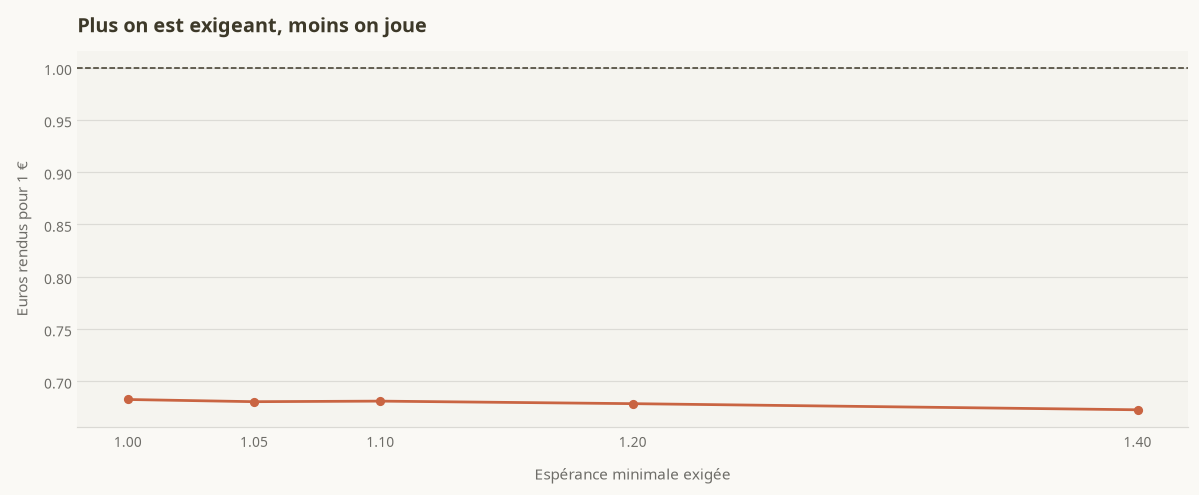

In [10]:
seuils = [1.0, 1.05, 1.1, 1.2, 1.4]
selectif = []
for seuil in seuils:
    meilleur = une_mise(test, test["ev_profil"])
    retenu = meilleur[meilleur["_score"] >= seuil]
    selectif.append(decrire(retenu, f"Espérance d'au moins {seuil:.2f}".replace(".", ","), n_test))
bilan_seuils = pd.DataFrame(selectif).set_index("Règle")
display(
    tableau(
        bilan_seuils,
        "2026 : ne jouer que si le profil voit un prix trop généreux",
        formats=FORMATS_REGLES,
    )
)

fig, ax = figure("Plus on est exigeant, moins on joue", (11, 4.6))
ax.plot(
    [1.0, 1.05, 1.1, 1.2, 1.4],
    bilan_seuils["Euros rendus pour 1 €"],
    color=THEME["primary"],
    marker="o",
    linewidth=1.8,
)
ax.axhline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ax.set_xlabel("Espérance minimale exigée")
ax.set_ylabel("Euros rendus pour 1 €")
ax.set_xticks([1.0, 1.05, 1.1, 1.2, 1.4])
fig.tight_layout()


**À retenir.** Monter le seuil ne filtre presque rien. À 1,40 encore, on joue 99 % des
courses, toujours autour d'une cote 68, pour 0,67 € rendus. Le profil voit un écart sur
presque chaque course, parce qu'il surévalue les outsiders. L'exigence ne crée pas un prix :
**elle laisse passer le plus long.**


<a id="limites"></a>
## 6. Ce qu'il ne faut pas conclure trop vite


In [11]:
limites = pd.DataFrame(
    [
        (
            "La cote au départ est un prix de dernière minute",
            "Elle sert ici de prix encaissé. Un avis donné le matin ne pourrait pas s'en servir : seule la cote de la veille serait honnête, et elle est moins précise.",
        ),
        (
            "Un euro à plat n'est pas une gestion de mise",
            "On ne met pas plus d'argent sur les écarts les plus grands. Une mise proportionnelle à l'écart changerait les montants, pas le fait qu'un prix soit bon ou mauvais.",
        ),
        (
            "L'outsider gagnant pèse très lourd",
            "Une cote à 40 qui tombe une fois déplace le cumul de 40 €. La marge de hasard sert à ne pas prendre ce coup pour une méthode.",
        ),
        (
            "Le modèle est volontairement simple",
            "Il ignore le driver, l'entraîneur, la musique récente calculée sans regarder le futur, et les mouvements d'argent. Un écart de prix, s'il existe, est peut-être là — pas dans la cote elle-même.",
        ),
        (
            "Les chevaux reviennent",
            "Le même nom court des dizaines de fois. Une partie de ce que le modèle « sait » est une mémoire des habitués, pas une lecture de la course du jour.",
        ),
        (
            "Le placé et les combinés sont un autre jeu",
            "Un outsider peut être une mauvaise affaire au gagnant et une autre question au couplé. Ce document ne tranche que le simple gagnant.",
        ),
    ],
    columns=["Point de vigilance", "Pourquoi ça compte"],
).set_index("Point de vigilance")
display(
    tableau(
        limites,
        "Avant de parler d'une chasse aux outsiders",
        formats={"Pourquoi ça compte": "{}"},
    )
)


,Pourquoi ça compte
Point de vigilance,
La cote au départ est un prix de dernière minute,"Elle sert ici de prix encaissé. Un avis donné le matin ne pourrait pas s'en servir : seule la cote de la veille serait honnête, et elle est moins précise."
Un euro à plat n'est pas une gestion de mise,"On ne met pas plus d'argent sur les écarts les plus grands. Une mise proportionnelle à l'écart changerait les montants, pas le fait qu'un prix soit bon ou mauvais."
L'outsider gagnant pèse très lourd,Une cote à 40 qui tombe une fois déplace le cumul de 40 €. La marge de hasard sert à ne pas prendre ce coup pour une méthode.
Le modèle est volontairement simple,"Il ignore le driver, l'entraîneur, la musique récente calculée sans regarder le futur, et les mouvements d'argent. Un écart de prix, s'il existe, est peut-être là — pas dans la cote elle-même."
Les chevaux reviennent,"Le même nom court des dizaines de fois. Une partie de ce que le modèle « sait » est une mémoire des habitués, pas une lecture de la course du jour."
Le placé et les combinés sont un autre jeu,Un outsider peut être une mauvaise affaire au gagnant et une autre question au couplé. Ce document ne tranche que le simple gagnant.


**À retenir.** Rien de tout cela n'interdit de chercher un prix mal ajusté. Cela interdit
de confondre une cote élevée avec une bonne affaire, et un beau cumul sur peu de courses
avec une méthode.


<a id="verdict"></a>
## 7. Verdict


In [12]:
verdict = pd.DataFrame(
    [
        (
            "Juger une règle au nombre de vainqueurs",
            "Utile pour classer",
            "Le favori trouve le vainqueur dans 34 % des courses de 2026 et ne rend que 0,94 €. Le taux de réussite et l'argent rendu ne désignent pas la même règle.",
        ),
        (
            "Jouer le plus gros outsider",
            "Non",
            "0,60 € sur toute la période, 0,69 € en 2026. Cote médiane autour de 70. Le prix le plus haut est le plus mauvais achat, et la marge de hasard ne le rattrape pas.",
        ),
        (
            "Descendre de quelques rangs sous le favori",
            "Non",
            "Du 2e au 6e prix, le rendement baisse, de 0,92 € à 0,82 €. Il n'y a pas de rang intermédiaire bénéficiaire.",
        ),
        (
            "Choisir l'espérance plutôt que la probabilité",
            "Le bon geste, si la chance est juste",
            "Sans la cote, l'espérance désigne l'outsider et rend 0,69 €. Avec la cote, elle s'arrête au 2e prix et rend 0,93 €, comme le favori. La formule ne vaut que si les chances baissent au moins aussi vite que 1 / cote.",
        ),
        (
            "Ne jouer que les écarts les plus nets",
            "Sans effet",
            "Même à 1,40, on joue encore 99 % des courses de 2026, sur des cotes de 68. Le seuil ne compense pas une chance trop généreuse pour les outsiders.",
        ),
    ],
    columns=["Question", "Réponse", "Lecture"],
).set_index("Question")
display(
    tableau(
        verdict,
        "Ce que l'on peut retenir pour la suite",
        formats={"Réponse": "{}", "Lecture": "{}"},
    )
)


,Réponse,Lecture
Question,,
Juger une règle au nombre de vainqueurs,Utile pour classer,"Le favori trouve le vainqueur dans 34 % des courses de 2026 et ne rend que 0,94 €. Le taux de réussite et l'argent rendu ne désignent pas la même règle."
Jouer le plus gros outsider,Non,"0,60 € sur toute la période, 0,69 € en 2026. Cote médiane autour de 70. Le prix le plus haut est le plus mauvais achat, et la marge de hasard ne le rattrape pas."
Descendre de quelques rangs sous le favori,Non,"Du 2e au 6e prix, le rendement baisse, de 0,92 € à 0,82 €. Il n'y a pas de rang intermédiaire bénéficiaire."
Choisir l'espérance plutôt que la probabilité,"Le bon geste, si la chance est juste","Sans la cote, l'espérance désigne l'outsider et rend 0,69 €. Avec la cote, elle s'arrête au 2e prix et rend 0,93 €, comme le favori. La formule ne vaut que si les chances baissent au moins aussi vite que 1 / cote."
Ne jouer que les écarts les plus nets,Sans effet,"Même à 1,40, on joue encore 99 % des courses de 2026, sur des cotes de 68. Le seuil ne compense pas une chance trop généreuse pour les outsiders."


L'objectif n'était pas de couronner un modèle. Du 1er janvier 2025 au 31 août 2026,
**aucune de ces règles ne rend la mise**. Le favori est la moins mauvaise : 0,94 €, et il
trouve le vainqueur une fois sur trois. L'outsider automatique est la pire : autour de
0,60 €.

Maximiser les gains change le cheval qu'on cherche : on ne lui demande plus d'être le plus
probable, on lui demande d'être **sous-payé**. Encore faut-il que la chance qu'on lui prête
descende quand la cote monte. Ici, elle ne descend pas assez. L'espérance désigne alors le
plus gros prix, et l'on a recréé, avec une formule, la règle qui perd le plus.

La piste utile n'est donc pas « jouer plus long ». C'est une chance estimée qui contredit
vraiment la cote, puis une mise seulement là où cette contradiction tient. Sur ce socle, cette
contradiction n'est pas là.
